# Zustandsgraph – Einstiegsbeispiel
Jupyter ist eine Umgebung für zellbasierte Datenanalyse und -visualisierung (meist mit Python). Alle verwendeten Werkzeuge sind kostenlos und Open-Source.

Mit der folgenden Taste kann der gesamte Code ausgeführt werden:

<img src="img/RunAll.png" width=800/>

## Autobahnfahrt mit dem E-Mobil, der Akku wird knapp.
100 km Autobahn, fünf Abschnitte à 20 km. Erlaubt sind die Tempostufen 60, 80, 100 und 120 km/h.
Bei Kilometer 40 bis 60 ist eine Baustelle: höchstens 80 km/h. Der Akku hat noch **15 kWh**.

Frage: Welches Tempo-Profil bringt uns ans Ziel, ohne liegenzubleiben, und ohne ewig unterwegs zu sein?

Genau dieselbe Frage stellt sich der Fahrerin auf der Rennstrecke. Und genau derselbe Code löst sie.

In [1]:
%matplotlib inline
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

## 1. Was ist uns wichtig? Zeit oder Energie?
Zwei Gewichte, zusammen 1. Spiel damit!

In [2]:
factor_time = 0.8          # schnell ankommen
factor_energy = 0.2        # Akku schonen
akku_Wh = 15000            # was noch im Akku ist [Wh]

## 2. Die Strecke als Wegpunkte
`vmax` = Tempolimit (Sicherheit), `vmin` = Mindesttempo (Verkehrsfluss, Zeitbudget).

In [3]:
section_length = 20        # [km]   ein Abschnitt
velocity_spacing = 20      # [km/h] eine Tempostufe
max_acceleration = 1       # Stufen, die man pro Abschnitt rauf oder runter darf

waypoints = [
    {"s": 0,   "vmax": 0,   "vmin": 0},     # Start: wir stehen auf der Auffahrt
    {"s": 20,  "vmax": 120, "vmin": 60},
    {"s": 40,  "vmax": 80,  "vmin": 60},    # Baustelle
    {"s": 60,  "vmax": 80,  "vmin": 60},    # Baustelle
    {"s": 80,  "vmax": 120, "vmin": 60},
    {"s": 100, "vmax": 120, "vmin": 60},    # Ziel: Ausfahrt mit Tempo erlaubt
]
config = pd.DataFrame(waypoints)
x_max = len(config.index) - 1
print(config)

     s  vmax  vmin
0    0     0     0
1   20   120    60
2   40    80    60
3   60    80    60
4   80   120    60
5  100   120    60


## 3. Was kostet ein Übergang? Die predict-Funktion
Später steht hier das physikalische Modell des Rennwagens. Heute reichen drei Zeilen Physik:
Zeit = Weg / mittleres Tempo. Energie = Fahrwiderstand (Rollen konstant, Luft wächst mit dem Quadrat des Tempos, über den Weg gemittelt) + Beschleunigungsenergie.

In [5]:
car_mass = 1800            # [kg]   E-Mobil mit Fahrerin

def predict(v1, v2, section_length):
    v_mean = (v1 + v2) / 2                                  # [km/h] Durchschnittsgeschwindigkeit
    time = section_length / v_mean                          # [h]    Zeit für Strecke: Weg durch mittleres Tempo
    v_sq_mean = (v1**2 + v2**2) / 2                         # [km²/h²] Mittel von v² über den Weg (v² linear in s bei konstanter Beschleunigung)
    wh_per_km = 100 + 0.0085 * v_sq_mean                    # [Wh/km] Roll- + Luftwiderstand (wächst mit Tempo²)
    E_drive = wh_per_km * section_length                    # [Wh] Fahrenergie ist der gesamte Widerstand mal Strecke
    E_kin = 0.5 * car_mass * ((v2/3.6)**2 - (v1/3.6)**2) / 3600   # [Wh] Beschleunigen benötigt zusäzliche Kinetische Energie, Bremsen gibt Energie zurück
    E_kin = E_kin if E_kin > 0 else 0.6 * E_kin             # Rekuperation holt 60 % zurück
    return E_drive + E_kin, time

## 4. Den Graphen bauen: Knoten = Zustände, Kanten = Übergänge mit Kosten
Ein Zustand ist «bei Kilometer x mit Tempo k·20 unterwegs». Der Name `x2_k4` heisst: Abschnitt 2, Stufe 4 = 80 km/h.

In [6]:
G = nx.DiGraph()
G.add_node("x0_k0", v=0)                                     # Startknoten
coordinate_set_dict = {"x0_k0": (0, 0)}                      # nur fürs Bild

for x in range(1, x_max + 1):                                # über alle Abschnitte
    k_min = int(np.ceil(config.loc[x, "vmin"] / velocity_spacing))
    k_max = int(np.floor(config.loc[x, "vmax"] / velocity_spacing))

    for k in range(k_min, k_max + 1):                        # über alle erlaubten Tempostufen
        v = k * velocity_spacing
        node_name = f"x{x}_k{k}"
        G.add_node(node_name, v=v)
        coordinate_set_dict[node_name] = (x * section_length, v)

        vorgaenger = [0] if x == 1 else range(k - max_acceleration, k + max_acceleration + 1)
        for kold in vorgaenger:                              # von wo aus kommt man hierher?
            if G.has_node(f"x{x-1}_k{kold}"):
                vold = kold * velocity_spacing
                E, time = predict(vold, v, section_length)
                cost_time = time / (section_length / 60)     # 1 = so lange wie mit 60 km/h
                cost_energy = E / 4500                       # 1 = so viel wie mit 120 km/h
                edge_weight = factor_time * cost_time + factor_energy * cost_energy
                G.add_edge(f"x{x-1}_k{kold}", node_name, weight=edge_weight, time=time, energy=E)

print(G.number_of_nodes(), "Knoten,", G.number_of_edges(), "Kanten")

17 Knoten, 28 Kanten


## 5. Den günstigsten Weg suchen: Dijkstra
Dijkstra findet den Pfad vom Start zu einem Zielknoten mit der kleinsten Summe aller Kantengewichte.
Wir lassen ihn für jedes mögliche Ankunftstempo rechnen und nehmen das günstigste.

In [7]:
ziele = [n for n in G.nodes if n.startswith(f"x{x_max}_")]
nodelist = min((nx.dijkstra_path(G, "x0_k0", z) for z in ziele),
               key=lambda p: nx.path_weight(G, p, "weight"))

profil = [G.nodes[n]["v"] for n in nodelist]
total_time = sum(G.edges[u, v]["time"] for u, v in zip(nodelist[:-1], nodelist[1:]))
total_energy = sum(G.edges[u, v]["energy"] for u, v in zip(nodelist[:-1], nodelist[1:]))

print("Tempo-Profil [km/h]:", profil)
print(f"Fahrzeit: {total_time*60:.0f} min   Energie: {total_energy/1000:.1f} kWh   Akku: {akku_Wh/1000:.1f} kWh")
print("Kommen wir an?", "Ja." if total_energy <= akku_Wh else "Nein, wir bleiben liegen!")

Tempo-Profil [km/h]: [0, 100, 80, 80, 100, 120]
Fahrzeit: 77 min   Energie: 17.1 kWh   Akku: 15.0 kWh
Kommen wir an? Nein, wir bleiben liegen!


## 6. Das Bild: alle Zustände, alle Übergänge, der beste Weg

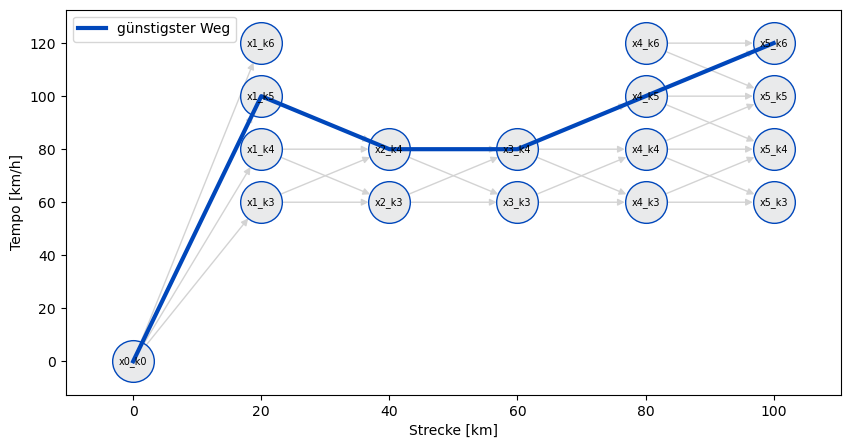

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
nx.draw(G, pos=coordinate_set_dict, ax=ax, with_labels=True, font_size=7,
        node_color="#E9EAEB", edgecolors="#0047BB", edge_color="lightgrey", node_size=900)
ax.plot([x * section_length for x in range(len(profil))], profil, color="#0047BB", linewidth=3, label="günstigster Weg")
ax.set_xlabel("Strecke [km]"); ax.set_ylabel("Tempo [km/h]"); ax.axis("on"); ax.legend()
plt.tick_params(axis="both", which="both", bottom=True, left=True, labelbottom=True, labelleft=True)
plt.show()

## Zum Spielen
* Setze `factor_time = 0.8`, `factor_energy = 0.2`: Was passiert mit dem Profil, und reicht der Akku noch?
* Verlege die Baustelle oder mach sie länger.
* Erlaube `max_acceleration = 2`: Welche neuen Kanten entstehen?
* Setze `akku_Wh = 13000`: Welche Gewichte brauchst du, damit du ankommst?